# MNIST: UMAP on raw pixels, supervised UMAP and metric learning

Code for the [MNIST examples](https://gprietos.github.io/posts/umap/#mnist-dataset) of the post [Dimensionality Reduction & Embedding Visualization — UMAP](https://gprietos.github.io/posts/umap/).

MNIST has 70,000 handwritten digits, split into 60,000 for training and 10,000 for testing, each a 28×28 grayscale image. Each image is flattened into a vector of 784 pixel values, and two images are close if their pixels are close in Euclidean distance. UMAP builds its neighbor graph from those distances ([graph construction](https://gprietos.github.io/posts/umap/#graph-construction)) and lays the graph out in 2-D or 3-D.

The notebook follows the post:
1. **3-D UMAP** of the 10,000 test digits, each drawn as its own image (the post's interactive figure).
2. **Unsupervised vs. supervised UMAP**: the same digits laid out without and with their labels.
3. **Metric learning**: fit UMAP on the training digits, place the test digits without their labels, and classify them by their nearest neighbors.
4. Extra: The post's **cover image**.

The MNIST dataset (about 50 MB) is downloaded into `data/mnist/` automatically. The first run fits several UMAPs, and the two on the 60,000 training digits take a few minutes each. Results are cached in `data/cache/`, so later runs only load them. Results are also stored in the FiftyOne dataset `mnist`, to browse in the FiftyOne App at the end.

In [ ]:
import fiftyone as fo
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown

from umap_examples.config import FIGURES_DIR, MNIST3D_DIR, SEED
from umap_examples.mnist import export_mnist_3d, knn_predict, load_dataset, load_mnist, split_view, store_predictions
from umap_examples.plotting import plot_digit_mosaic, plot_scatter, save_figure
from umap_examples.reduction import compute_umap, store_points
from umap_examples.widgets import show_mnist_3d

INTERACTIVE = True  # launch the FiftyOne App for interactive visualization at the end

## Load

The pixels of each digit as a vector of 784 values in [0, 1] (60,000 training and 10,000 test digits), and the same digits as images in FiftyOne, in the same order.

In [ ]:
X_train, y_train = load_mnist(train=True)
X_test, y_test = load_mnist(train=False)

dataset = load_dataset()
train_view, test_view = split_view(dataset, "train"), split_view(dataset, "test")
X_train.shape, X_test.shape

((60000, 784), (10000, 784))

## 3-D UMAP of the test digits

The 10,000 test digits embedded in 3-D with UMAP's defaults, k = 15 neighbors and min_dist = 0.1. Each point is drawn as the digit itself, colored by its label. 

You can drag to rotate, scroll to zoom, and select a digit below the plot to highlight it (shift-click to add more). Here, only a static preview is shown, rerun the cell to see the intereactive figure or see it in the post.

Note that this plot shows default unsupervised UMAP and the labels are only used for the colors. Most digits form their own cluster and some clusters are close to each other, such as 4 and 9, or 3, 5 and 8, since these digits share similar shapes. The exact distances between clusters don't mean much though, as seen in [UMAP weaknesses](https://gprietos.github.io/posts/umap/#umap-weaknesses) in the post.

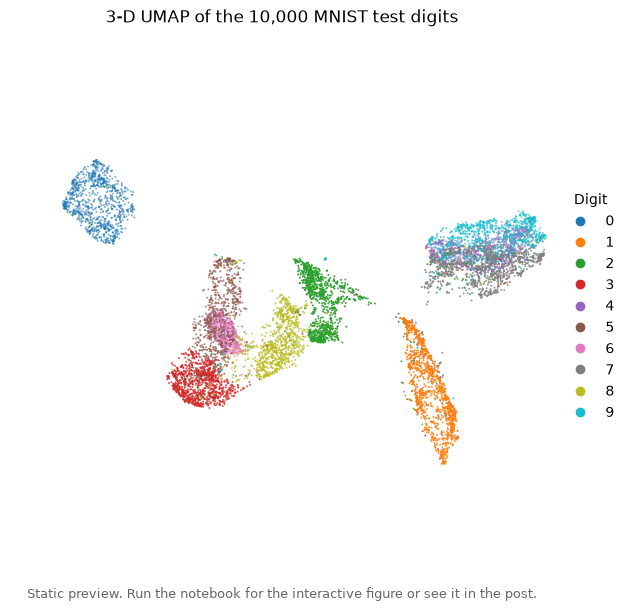

In [ ]:
if not (MNIST3D_DIR / "mnist_3d.json").exists():
    export_mnist_3d()  # 3-D UMAP and a sprite sheet of the digits, into blog/assets/data/umap/mnist_3d/
show_mnist_3d()

## Unsupervised vs. supervised UMAP

The same 10,000 digits, now in 2-D, without and with their labels (check [supervised UMAP](https://gprietos.github.io/posts/umap/#umap-for-supervised-dimension-reduction-and-metric-learning) in the post). UMAP keeps the edges between digits with the same label and strongly down-weights the edges between different labels. The layout optimization is the same, so with the edges between classes down-weighted, they barely pull anymore and the repulsion pushes the classes apart.

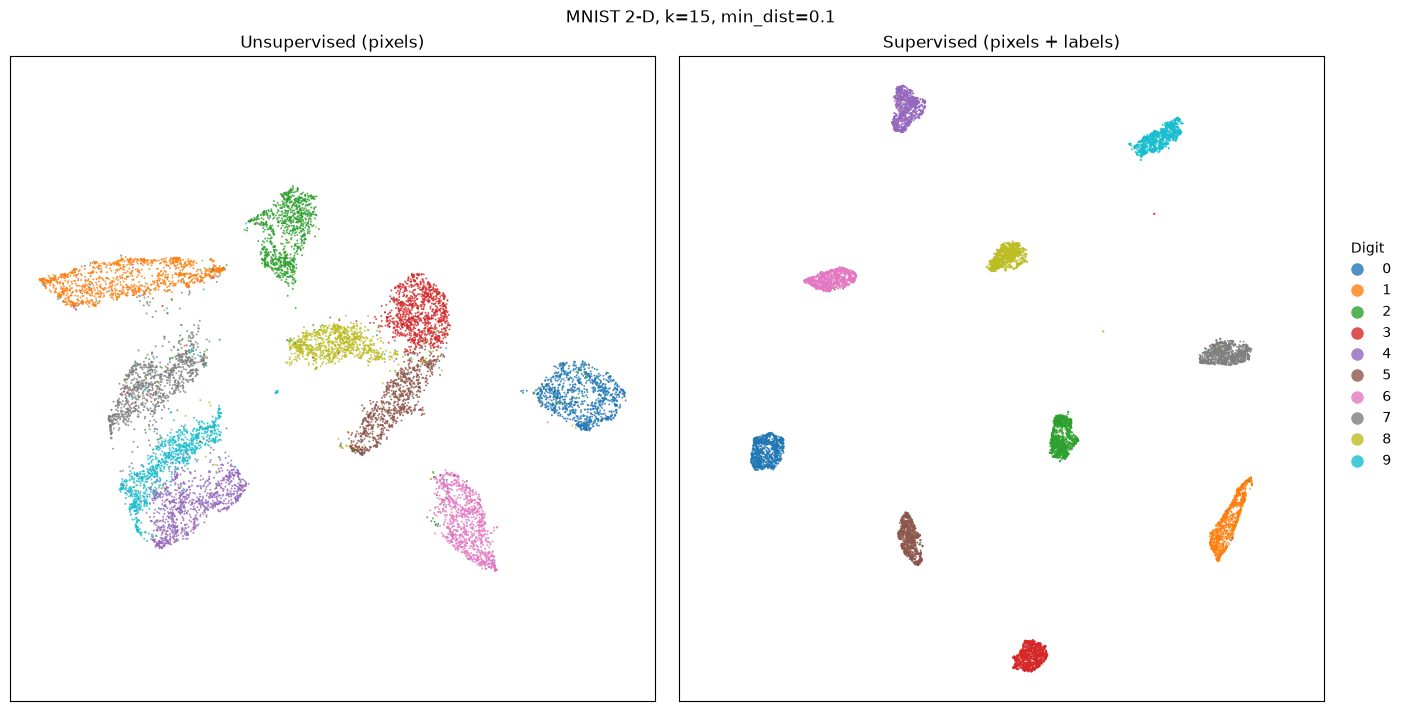

In [ ]:
points_unsup, _ = compute_umap(X_test, metric="euclidean")
points_sup, _ = compute_umap(X_test, metric="euclidean", y=y_test)
store_points(test_view, points_unsup, "umap_test_unsup")
store_points(test_view, points_sup, "umap_test_sup")

fig, axes = plt.subplots(1, 2, figsize=(14, 7), layout="constrained")
plot_scatter(points_unsup, y_test, ax=axes[0], title="Unsupervised (pixels)", legend=False)
plot_scatter(points_sup, y_test, ax=axes[1], title="Supervised (pixels + labels)", legend=False)
fig.suptitle("MNIST 2-D, k=15, min_dist=0.1")
fig.legend(*axes[0].collections[0].legend_elements(), loc="outside right center",
           frameon=False, markerscale=1.5, title="Digit")
save_figure(fig, "mnist_unsup_vs_sup", dark=True)
plt.show()

With labels, each digit forms its own cluster, clearly separated from the others. This separation is artificial, though. It comes from the labels we gave UMAP, not from the pixel data itself, so a clean supervised plot is no evidence that the data separates the classes.

## Semi-supervised

Labels can also be partly unknown, marked as `-1`. Edges that touch a digit with an unknown label are only moderately down-weighted. The more labels UMAP knows, the further apart it pushes the digit clusters. With half of the labels, the map still looks much like the unsupervised one. With three quarters, most digits already form their own cluster, and with all of them, every digit is clearly separated.

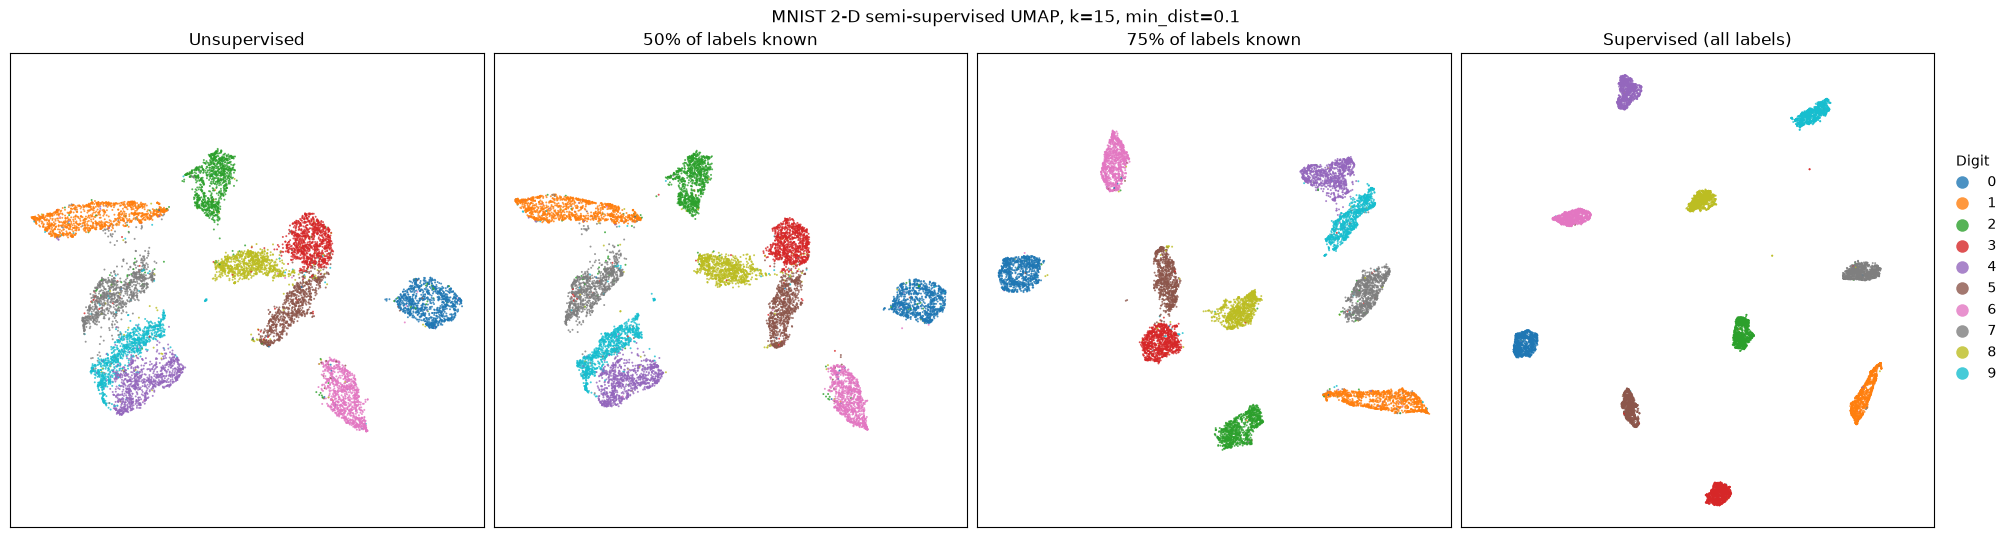

In [ ]:
layouts = {"Unsupervised": points_unsup}
for known in [0.5, 0.75]:
    y_known = y_test.copy()
    y_known[np.random.default_rng(SEED).random(len(y_known)) < 1 - known] = -1
    layouts[f"{known:.0%} of labels known"] = compute_umap(X_test, metric="euclidean", y=y_known)[0]
layouts["Supervised (all labels)"] = points_sup

fig, axes = plt.subplots(1, len(layouts), figsize=(5 * len(layouts), 5.4), layout="constrained")
for ax, (title, points) in zip(axes, layouts.items()):
    plot_scatter(points, y_test, ax=ax, title=title, legend=False)
fig.suptitle("MNIST 2-D semi-supervised UMAP, k=15, min_dist=0.1")
fig.legend(*axes[0].collections[0].legend_elements(), loc="outside right center",
           frameon=False, markerscale=1.5, title="Digit")
plt.show()

## Metric learning

If digits of the same class end up next to each other in the labeled embedding, new digits can be classified by their nearest neighbors in it (check [metric learning](https://gprietos.github.io/posts/umap/#umap-for-supervised-dimension-reduction-and-metric-learning) in the post). To test this, we first fit UMAP on the 60,000 training digits, with and without labels, and then place the 10,000 test digits in the learned embeddings without their labels. During optimization, the training digits stay fixed.

In [ ]:
points_train_unsup, umap_unsup = compute_umap(X_train, metric="euclidean")
points_train_sup, umap_sup = compute_umap(X_train, metric="euclidean", y=y_train)
points_test_unsup = umap_unsup.transform(X_test)
points_test_sup = umap_sup.transform(X_test)

store_points(train_view, points_train_unsup, "umap_train_unsup")
store_points(train_view, points_train_sup, "umap_train_sup")
store_points(test_view, points_test_unsup, "umap_test_unsup_transform")
store_points(test_view, points_test_sup, "umap_test_sup_transform")

### kNN accuracy on the test digits

Each test digit gets the majority label of its 5 nearest training digits, measured in three ways:
- **raw pixels** (784-D)
- **2-D UMAP without labels**: what squeezing the pixel distances into 2-D costs
- **2-D UMAP with labels**: what laying out the training digits with their labels adds


In [ ]:
features = {
    "knn_pixels": ("Raw pixels (784-D)", X_train, X_test),
    "knn_umap_unsup": ("2-D UMAP, without labels", points_train_unsup, points_test_unsup),
    "knn_umap_sup": ("2-D UMAP, with labels", points_train_sup, points_test_sup),
}
preds, rows = {}, []
for field, (name, A_train, A_test) in features.items():
    preds[field] = knn_predict(A_train, y_train, A_test)
    store_predictions(test_view, field, preds[field])
    rows.append(f"| {name} | {(preds[field] == y_test).mean():.1%} |")
Markdown("\n".join(["| Distances used by kNN | Accuracy |", "| --- | --- |", *rows]))

| Distances used by kNN | Accuracy |
| --- | --- |
| Raw pixels (784-D) | 96.9% |
| 2-D UMAP, without labels | 95.5% |
| 2-D UMAP, with labels | 95.9% |

### Training layout and test digits

The 60,000 training digits are laid out using their labels, and the 10,000 test digits are then placed in that layout without theirs. Both are colored by their true digit label.

Since test digits are placed by their nearest training digits in pixel space, any of them whose nearest training digits belong to another class lands in that class's cluster, whatever it really is. The differently colored dots inside the clusters, for example the 4s in the 9s cluster and the 7s among the 1s, are the errors we saw earlier in the 2-D kNN classification. The most frequent confusions are listed below the figure.

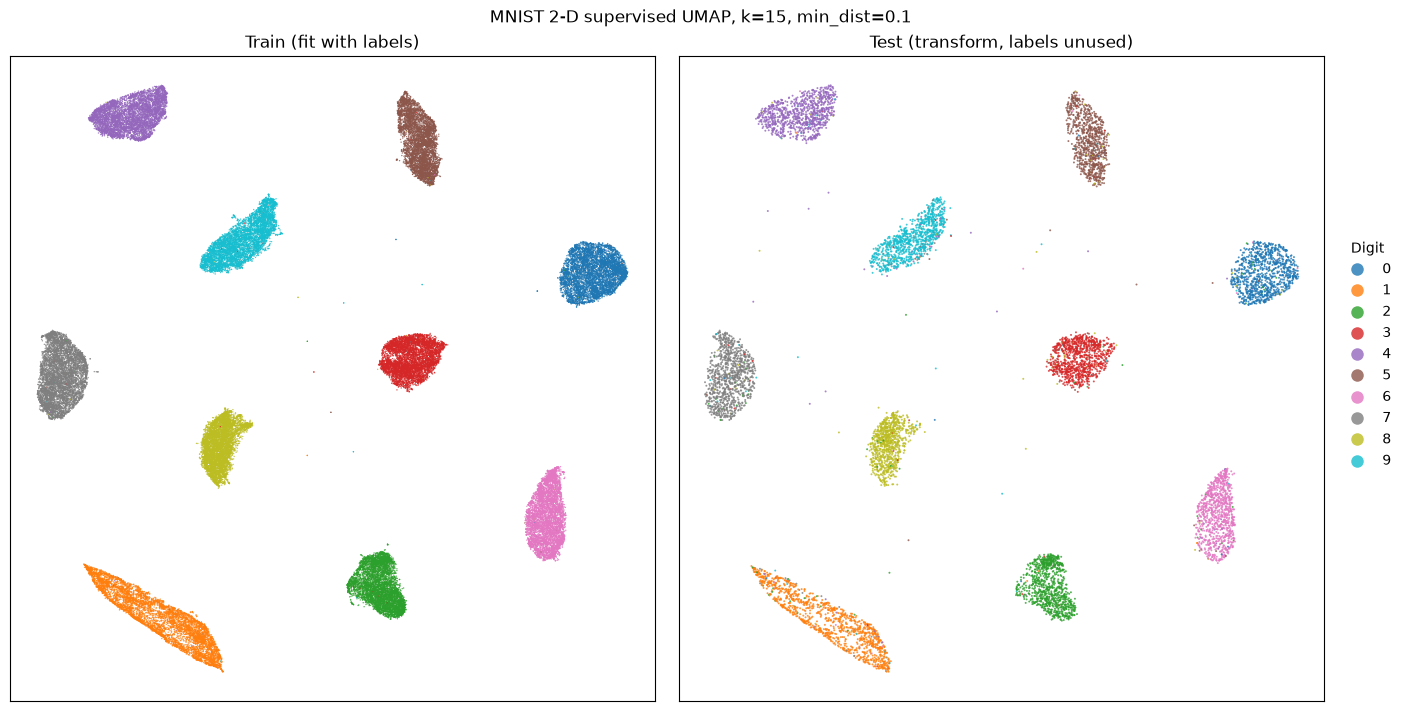

**Most frequent confusions**

| True digit | Predicted as | Count |
| --- | --- | --- |
| 4 | 9 | 32 |
| 7 | 1 | 28 |
| 8 | 3 | 20 |
| 2 | 7 | 18 |
| 2 | 1 | 17 |
| 7 | 9 | 15 |
| 2 | 0 | 14 |
| 8 | 5 | 13 |

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), layout="constrained")
plot_scatter(points_train_sup, y_train, ax=axes[0], s=1, title="Train (fit with labels)", legend=False)
plot_scatter(points_test_sup, y_test, ax=axes[1], s=2, title="Test (transform, labels unused)", legend=False)
fig.suptitle("MNIST 2-D supervised UMAP, k=15, min_dist=0.1")
fig.legend(*axes[0].collections[0].legend_elements(), loc="outside right center",
           frameon=False, markerscale=1.5, title="Digit")
save_figure(fig, "mnist_metric_learning", dark=True)
plt.show()

wrong = preds["knn_umap_sup"] != y_test
pairs, counts = np.unique(np.stack([y_test[wrong], preds["knn_umap_sup"][wrong]], 1), axis=0, return_counts=True)
top = sorted(zip(pairs, counts), key=lambda x: -x[1])[:8]
Markdown("\n".join(["**Most frequent confusions**", "", "| True digit | Predicted as | Count |", "| --- | --- | --- |",
                    *(f"| {t} | {p} | {c} |" for (t, p), c in top)]))

With 2 coordinates per digit instead of 784 pixels, neighbor search is much cheaper and we can see where each new digit lands, at the cost of accuracy. The loss is small here since MNIST is a simple dataset, but it could be larger for more complex data.

Using labels during training barely improves the accuracy. The test digits have no labels, so where they are placed is decided by their pixels, not by the labels.

## Extra: The post's cover

The 2-D unsupervised UMAP of the test digits from above, with some of the digits drawn as images at their positions. Digits are picked in random order and skipped if they would overlap one already drawn, so each cluster shows a few dozen readable digits.

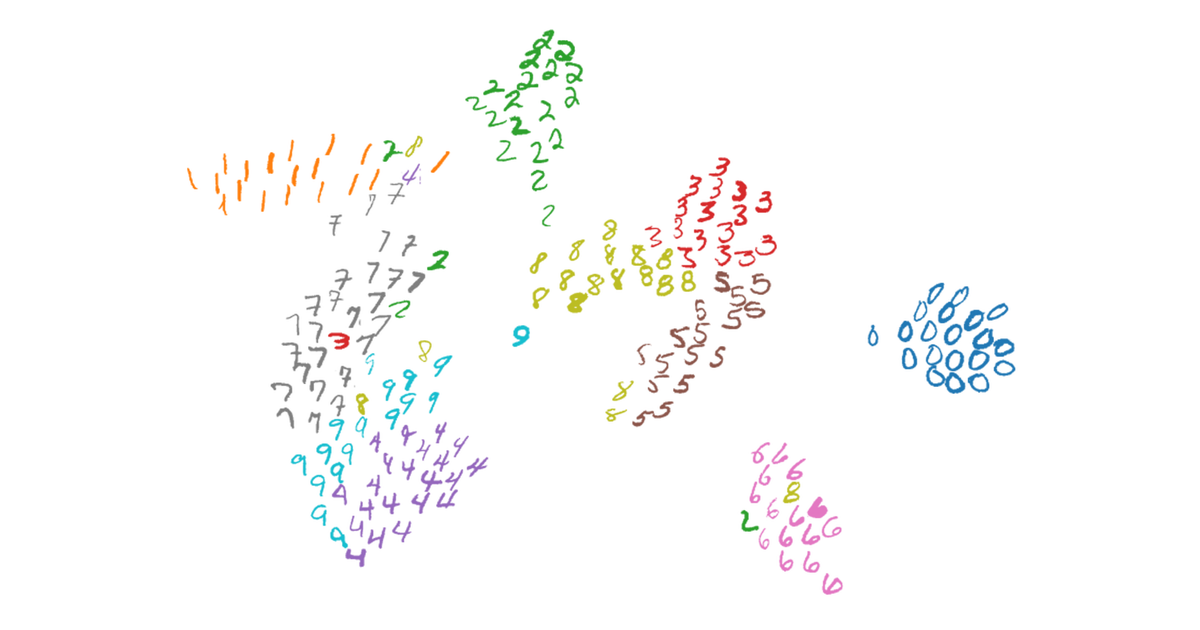

In [ ]:
cover = plot_digit_mosaic(points_unsup, X_test, y_test)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
cover.save(FIGURES_DIR / "cover_mnist.png")
cover.resize((1200, 630))

## Browse in FiftyOne

The FiftyOne App shows the UMAP layouts next to the images. After running the cell below:

1. **Open the Embeddings panel:** click the **+** next to the **Samples** tab at the top and choose **Embeddings**.
2. **Pick a layout:** in the panel's first dropdown, choose a run, for example `umap_test_sup_transform` (the test digits placed in the supervised layout).
3. **Color the points:** in **Color by**, choose `ground_truth` to color each digit by its true label.
4. **See the images:** lasso a region of the plot, and the grid shows only those digits.
5. **Show only the kNN mistakes:** in the sidebar on the left, open the dropdown menu that contains `eval_knn_umap_sup`, click the field and tick **False**. Only the 408 test digits that the 2-D kNN with labels got wrong remain, in the grid and in the plot.

In [ ]:
if INTERACTIVE:
    session = fo.launch_app(dataset)